# Шаг 1. Знакомимся с MNIST: 70 000 рукописных цифр 28 × 28

**MNIST** — самый известный учебный набор данных в машинном обучении: рукописные цифры от 0 до 9,
написанные школьниками и сотрудниками бюро переписи США. Каждая картинка — серый квадрат 28 × 28 пикселей,
и к каждой приложен **правильный ответ** (метка) — какая это цифра.

Набор заранее разделён на две части:
- **обучающая** (60 000 картинок) — на ней сеть учится;
- **проверочная** (10 000 картинок) — их сеть никогда не видит при обучении; на них честно проверяем, чему она научилась.

**Структура ноутбука (алгоритм):**
1. Импортируем matplotlib и помощники из `common.py`.
2. Загружаем обе части MNIST и считаем картинки.
3. Берём первую картинку: смотрим её форму и метку.
4. Рисуем её символами прямо в выводе — чтобы убедиться, что картинка — это таблица чисел.
5. Рисуем таблицу из первых 32 картинок с подписями и сохраняем в `mnist_grid.png`.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session03")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.MNIST(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех ноутбуках этой сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `mnist(train)` | скачивает (один раз, ~12 МБ в папку `data`) и возвращает набор MNIST: обучающий (`train=True`, 60 000) или проверочный (`train=False`, 10 000) |
| `MLP` | многослойная сеть: 784 входа → 128 → 64 → 10 выходов |
| `train(model, dataset, epochs)` | цикл обучения из шага 3, без пояснений |
| `predict_all(model, dataset)` | ответы сети (номер цифры) для каждой картинки набора |
| `accuracy(model, dataset)` | доля картинок, на которых сеть ответила верно |
| `load_model()` | загрузить обученную сеть из `mlp.pt` (файл создаёт шаг 3) |
| `show()` | показать графики matplotlib и закрыть их |
| `MODEL_FILE` | путь к файлу `mlp.pt` |

> Ноутбуки нужно запускать из папки `session03`, иначе `import common` не найдёт модуль.
> Нужные библиотеки: `pip install -r requirements.txt`.

## 1. Импорт

- `matplotlib.pyplot` (`plt`) — библиотека для графиков и показа картинок.
- Из `common` берём `mnist` (загрузка данных) и `show` (показ графиков).

In [6]:
import matplotlib.pyplot as plt

from common import mnist, show

## 2. Загружаем данные

`mnist(train=True)` возвращает объект-набор (`Dataset`) из библиотеки `torchvision`.
При первом запуске файлы скачаются из интернета в папку `data` — это займёт немного времени.
`len(набор)` — сколько в нём картинок.

In [7]:
train = mnist(train=True)   # при первом запуске скачается ~12 МБ в папку data
test = mnist(train=False)

print("Картинок для обучения:", len(train))
print("Картинок для проверки:", len(test))

Картинок для обучения: 60000
Картинок для проверки: 10000


## 3. Одна картинка изнутри

`train[0]` — первый элемент набора: пара **(картинка, метка)**.

- Картинка — это **тензор** PyTorch (многомерный массив, как в NumPy) формы `(1, 28, 28)`:
  1 канал (серый), 28 строк, 28 столбцов.
- Преобразование `transforms.ToTensor()` в `common.py` перевело числа из 0…255 в **0…1**: 0 — чёрный фон, 1 — белый штрих.
- Метка — обычное целое число от 0 до 9.

In [8]:
img, label = train[0]
print("Форма одной картинки:", tuple(img.shape), "— 1 канал, 28×28 пикселей")
print("Это цифра:", label)

Форма одной картинки: (1, 28, 28) — 1 канал, 28×28 пикселей
Это цифра: 5


## 4. Рисуем цифру символами

`img[0]` убирает канал и оставляет таблицу 28 × 28. Перебираем её строки, и для каждого числа печатаем
`██`, если пиксель светлее 0.5, или `··`, если темнее. Получается цифра из символов —
наглядное доказательство, что для компьютера картинка — это просто 784 числа.

In [9]:
# Картинка — таблица чисел от 0 до 1. Нарисуем её символами прямо в выводе
for row in img[0]:
    print("".join("██" if v > 0.5 else "··" for v in row))

························································
························································
························································
························································
························································
··································████··██████··········
······················████████████████████████··········
················████████████████████····················
················████████████████████····················
··················██··██████······██····················
······················████······························
······················██████····························
························████····························
··························██████························
····························██████······················
······························████████··················
··································██████················
·······························

## 5. Таблица из 32 цифр

`plt.subplots(4, 8)` создаёт фигуру с сеткой 4 × 8 маленьких графиков (`axes`).
`axes.flat` перебирает их по очереди, а `enumerate` даёт номер `i` — по нему берём `i`-ю картинку.

Для каждой ячейки:
- `ax.imshow(image[0], cmap="gray")` — показать картинку в оттенках серого;
- `ax.set_title(digit)` — подписать правильный ответ;
- `ax.axis("off")` — убрать оси с делениями.

`plt.tight_layout()` раздвигает графики, чтобы подписи не налезали, а `plt.savefig` сохраняет фигуру в файл.

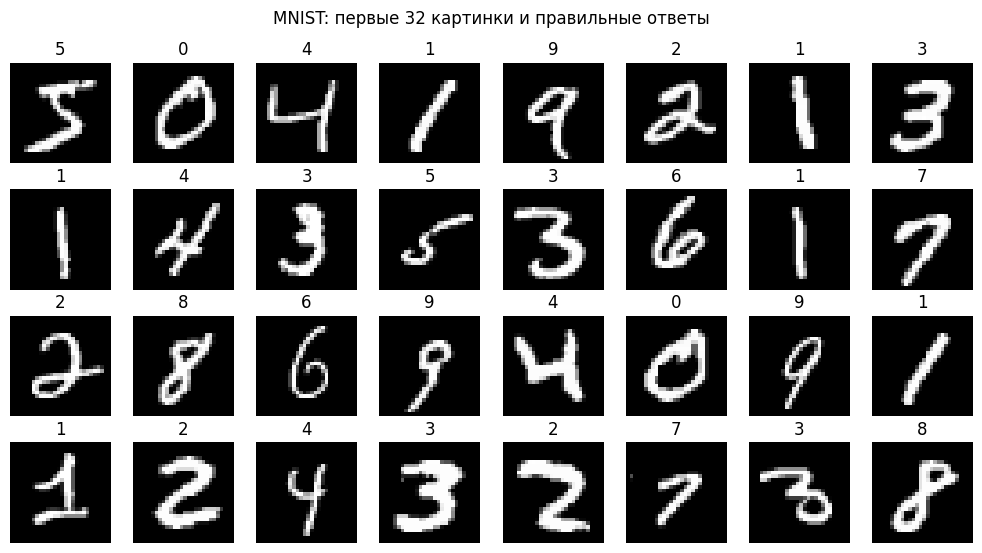

In [10]:
fig, axes = plt.subplots(4, 8, figsize=(10, 5.6))
for i, ax in enumerate(axes.flat):
    image, digit = train[i]
    ax.imshow(image[0], cmap="gray")
    ax.set_title(digit)
    ax.axis("off")
fig.suptitle("MNIST: первые 32 картинки и правильные ответы")
plt.tight_layout()
plt.savefig("mnist_grid.png", dpi=100)
show()

## Попробуйте сами

1. Нарисуйте символами не `train[0]`, а `train[7]` или `test[0]`.
2. Поменяйте порог `0.5` на `0.1` и `0.9`. Как меняется «толщина» цифры?
3. Посчитайте, сколько в обучающем наборе каждой цифры: `train.targets.bincount()`. Цифры встречаются поровну?
4. Найдите в таблице цифры, которые трудно узнать даже человеку.